**Comparative Evaluation | Industrial LLM Post-Training Study**

Goal: Compare the same unseen maintenance notes under identical prompts and greedy decoding for: Base Qwen → Continued Pretraining (CPT) → SFT → DPO. Optionally include the direct-SFT control (if Branch A was trained).

Contains:
1. Benchmark preparation:	10 synthetic test scenarios with 53 evidence checkpoints
2. Model inference:	Compare Base Qwen, CPT, SFT, DPO
3. Evidence Preservation Inspector:	Measure which reported observations were retained
4. Visual evaluation:	Two graphs and side-by-side report comparisons
5. Export results:	Save CSV, JSON, and plots for Streamlit

In [2]:
%pip install -q --upgrade unsloth peft safetensors pandas matplotlib datasets

In [3]:
import unsloth  # Import before transformers/PEFT, as in the bootcamp notebook.
import torch, gc, json, re, time
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from unsloth import FastLanguageModel
from IPython.display import display
from google.colab import drive

drive.mount('/content/drive')
ROOT = Path('/content/drive/MyDrive/llm-post-training-experimental-study')
OUT = ROOT / 'results' / 'evaluation_05'
OUT.mkdir(parents=True, exist_ok=True)
BASE = 'unsloth/Qwen2.5-1.5B-bnb-4bit'
STAGES = {
    'Base Qwen': BASE,
    'CPT': ROOT / 'models/stage1_non_instruction_adapter',
    'SFT': ROOT / 'models/stage2_domain_sft_adapter',
    'DPO': ROOT / 'models/stage3_dpo_adapter',
}
DIRECT_SFT = ROOT / 'models/stage2_sft_only_adapter'
if (DIRECT_SFT / 'adapter_config.json').exists():
    STAGES['Direct SFT'] = DIRECT_SFT  # Optional ablation; not fabricated.
assert torch.cuda.is_available(), 'Select Runtime > Change runtime type > GPU for inference.'
print('GPU:',torch.cuda.get_device_name(0))
print('Comparisons:',list(STAGES))
print('Output:',OUT)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1107 08:51:39.851000 922 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1107 08:51:39.869000 922 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Unsloth: xformers is installed but cannot load with torch 2.14.1+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
Mounted at /content/drive
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition
Comparisons: ['Base Qwen', 'CPT', 'SFT', 'DPO']
Output: /content/drive/MyDrive/llm-post-training-experimental-study/results/evaluation_05


**1. Make test set**

In [4]:
# Evidence is a short description plus conservative regular-expression synonyms.
# These are lexical proxies, not a judge of semantic correctness.
CASES = [
 {'id':'P-883','note':'Pump P-883 maintained steady discharge flow, but the casing briefly shuddered twice after a speed change. A clicking sound was heard at the discharge pipe support. The pressure display showed 4.1 bar and was described as normal. Bearing temperature was not measured; the unit remained online for monitoring.',
  'evidence':[('steady flow',[r'flow.*(?:steady|stable|constant)',r'(?:steady|stable).*flow']),('two shudders',[r'shudder',r'vibrat.*twice']),('clicking',[r'click']),('4.1 bar',[r'4\.1\s*bar']),('temperature missing',[r'temperat.*(?:not|missing|unavail)',r'no.*temperat']),('monitored',[r'monitor'])]},
 {'id':'HP-951','note':'Hydraulic press HP-951 briefly jerked while lowering its ram, although a gauge displayed the expected 86 bar. A soft hissing noise was reported near an actuator. The operator saw no oil puddle. No valve-response timing was logged. The press was shut down for inspection.',
  'evidence':[('jerking ram',[r'ram.*jerk',r'jerk.*ram',r'jerk']),('86 bar',[r'86\s*bar']),('hissing',[r'hiss']),('no oil puddle',[r'no.*(?:puddle|oil leak)',r'(?:puddle|leak).*not']),('timing unavailable',[r'(?:timing|response).*?(?:missing|not|unavail)',r'no.*timing']),('shut down',[r'shut.*down',r'stopp?ed'])]},
 {'id':'HX-842','note':'Heat exchanger HX-842 showed a gradual rise in outlet temperature, but inlet temperature remained steady. A small drip was seen at a flange. Flow rates were not recorded. The shift engineer suggested fouling but did not inspect the tubes.',
  'evidence':[('outlet temperature rise',['outlet.*temperat.*(?:ris|increas|high)','(?:ris|increas).*outlet.*temperat']),('steady inlet',['inlet.*(?:steady|stable|unchang)','(?:steady|stable).*inlet']),('flange drip',['(?:flange.*(?:drip|leak)|(?:drip|leak).*flange)']),('flow missing',['flow.*(?:missing|unavail|not record|unknown)','no.*flow']),('fouling unverified',['foul'])]},
 {'id':'CV-678','note':'Conveyor CV-678 tripped twice after restart. The belt briefly drifted toward the left guard. The drive motor was warm to the touch, but no temperature measurement was made. No visible belt tear was observed. It remained stopped.',
  'evidence':[('two trips',['trip.*twice','two.*trip','trip.*two']),('left drift',['drift.*left','left.*drift','belt.*left']),('warm motor',['motor.*warm','warm.*motor']),('no measurement',['no.*temperat','temperat.*(?:missing|not record|unavail)']),('no belt tear',['no.*(?:tear|damage)','tear.*not']),('stopped',['stop'])]},
 {'id':'GB-781','note':'Gearbox GB-781 emitted a short grinding sound on startup. An operator noted an oil-level indicator near its minimum mark; the sight glass was cloudy. No oil sample was collected. Running speed otherwise stayed constant.',
  'evidence':[('grinding',['grind']),('oil near minimum',['oil.*(?:minim|low)','(?:minim|low).*oil']),('cloudy sight glass',['(?:cloudy|cloud).*glass','glass.*(?:cloudy|cloud)']),('no oil sample',['(?:no|without).*oil.*sampl','oil.*sampl.*(?:not|missing)']),('constant speed',['speed.*(?:constant|stable|steady)'])]},
 {'id':'F-674','note':'Cooling fan F-674 stopped automatically following two current spikes. A blade tip showed a small superficial mark. An operator reported an unusual odor, with no visible smoke. Current-waveform logs were not available.',
  'evidence':[('two current spikes',['current.*spik','spik.*current']),('blade mark',['blade.*mark','mark.*blade']),('odor',['odor|odour|smell']),('no smoke',['no.*smoke','smoke.*(?:not|absent)']),('logs unavailable',['(?:log|waveform).*(?:missing|unavail|not)','(?:missing|unavail).*log'])]},
 {'id':'V-684','note':'Valve V-684 took longer than usual to close during a test. The position indicator briefly showed 15% open after a close command. No air-supply pressure reading was available. No external air leak was heard.',
  'evidence':[('slow closure',['(?:slow|delay|long).*clos','clos.*(?:slow|delay|long)']),('15% open',['15\s*%']),('no air pressure',['air.*pressure.*(?:no|missing|unavail)','no.*air.*pressure']),('no audible leak',['no.*(?:leak|hiss)','leak.*(?:not|absent)'])]},
 {'id':'M-768','note':'Mixer motor M-768 drew 12.4 A compared with the usual 9 A during a brief test. A mild burnt odor was noted. No insulation-resistance test was performed. The unit was switched off; the cause of the higher current is undetermined.',
  'evidence':[('12.4 amp',['12\.4\s*(?:a|amp)']),('usual 9 amp',['\b9\s*(?:a|amp)']),('burnt odor',['burn.*(?:odor|smell)','(?:odor|smell).*burn']),('no insulation test',['insulat.*(?:not|no|missing|unavail)','no.*insulat']),('switched off',['(?:switch|turn|shut).*off','stop'])]},
 {'id':'C-739','note':'Air compressor C-739 stopped at 02:10 after a metallic knock. Discharge temperature earlier measured 71 C, within its normal band. The operator claimed the piston was broken, but no internal inspection was done. The compressor stayed isolated.',
  'evidence':[('stopped at 02:10',['02:10','stopp?ed']),('metallic knock',['knock']),('71 C',['71\s*°?\s*c','71\s*degree']),('normal temperature',['temperat.*normal','normal.*temperat','71.*normal']),('unverified piston claim',['piston']),('isolated',['isolat'])]},
 {'id':'PLC-875','note':'PLC-875 recorded three intermittent communication faults over an hour. The operator interface froze once, then recovered without restart. Network latency measurements were not taken. An engineer suspected a damaged cable, but no cable inspection was completed.',
  'evidence':[('communication faults',['communicat.*fault','fault.*communicat']),('interface froze',['froze|freez|frozen']),('recovered',['recover']),('latency unavailable',['latenc.*(?:not|missing|unavail)','no.*latenc']),('cable unverified',['cable'])]},
]
print('Independent synthetic cases:',len(CASES),'| Total evidence items:',sum(len(c['evidence']) for c in CASES))
assert len({c['id'] for c in CASES}) == len(CASES)
assert all(c['evidence'] and c['note'] for c in CASES)

Independent synthetic cases: 10 | Total evidence items: 53


In [5]:
# LEAKAGE AUDIT: compare exact equipment IDs with both processed training datasets.
# This catches ID reuse, not paraphrase/semantic overlap.
ids = {c['id'] for c in CASES}
for filename in ['sft_prepared.jsonl','dpo_prepared.jsonl']:
    f = ROOT / 'data/processed' / filename
    assert f.exists(), f'Missing training dataset for leakage audit: {f}'
    text = f.read_text(encoding='utf-8')
    collisions = sorted(i for i in ids if re.search(r'(?<![A-Z0-9-])'+re.escape(i)+r'(?![A-Z0-9-])', text))
    print(filename, '| overlapping test IDs:',collisions)
    assert not collisions, 'STOP: benchmark IDs overlap with training; choose new IDs.'
print('PASS: No exact equipment-ID overlap. Still audit for scenario/wording overlap manually.')

sft_prepared.jsonl | overlapping test IDs: []
dpo_prepared.jsonl | overlapping test IDs: []
PASS: No exact equipment-ID overlap. Still audit for scenario/wording overlap manually.


**2. Inference**

In [6]:
SEED=42
MAX_SEQ_LENGTH=1024
MAX_NEW_TOKENS=512
RESULTS_PATH=OUT/'checkpoint_outputs.jsonl'
INSTRUCTION='Transform this technician note into a structured industrial maintenance report. Clearly distinguish observed evidence from unverified causes, identify missing information, and do not invent measurements or confirm faults.\n\nTechnician note: '

def make_prompt(note):
    return '### Instruction:\n'+INSTRUCTION+note+'\n\n### Response:\n'

# Important: evaluate with fixed output length and deterministic greedy decoding.
# Run once with CLEAN_START=True if you change prompts, checkpoints, or decoding settings.
CLEAN_START=False
if CLEAN_START and RESULTS_PATH.exists():
    RESULTS_PATH.unlink()

def read_results():
    return [json.loads(line) for line in RESULTS_PATH.read_text(encoding='utf-8').splitlines() if line.strip()] if RESULTS_PATH.exists() else []

def generate_report(model, tokenizer, prompt):
    inputs=tokenizer(prompt,return_tensors='pt').to(next(model.parameters()).device)
    with torch.inference_mode():
        output=model.generate(**inputs,max_new_tokens=MAX_NEW_TOKENS,do_sample=False,
                              pad_token_id=tokenizer.eos_token_id,eos_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(output[0,inputs['input_ids'].shape[1]:],skip_special_tokens=True).strip()

# Sanity check template (no tokenization yet).
print(make_prompt(CASES[0]['note'])[:550])

### Instruction:
Transform this technician note into a structured industrial maintenance report. Clearly distinguish observed evidence from unverified causes, identify missing information, and do not invent measurements or confirm faults.

Technician note: Pump P-883 maintained steady discharge flow, but the casing briefly shuddered twice after a speed change. A clicking sound was heard at the discharge pipe support. The pressure display showed 4.1 bar and was described as normal. Bearing temperature was not measured; the unit remained online f


In [7]:
# Running this cell may consume substantial GPU time. Completed results are cached.
existing = read_results()
expected = {(s,c['id']) for s in STAGES for c in CASES}
assert len({(r['stage'],r['id']) for r in existing}) == len(existing), 'Duplicate cached outputs: inspect file.'
assert {(r['stage'],r['id']) for r in existing} <= expected, 'Stale cache rows. Audit or set CLEAN_START=True.'
completed = {(r['stage'],r['id']) for r in existing}
for stage, checkpoint in STAGES.items():
    missing = [c for c in CASES if (stage,c['id']) not in completed]
    if not missing:
        print('CACHED:',stage); continue
    if stage!='Base Qwen':
        assert (Path(checkpoint)/'adapter_config.json').exists(), f'Missing adapter: {checkpoint}'
    print('Loading:',stage,'|',checkpoint,'| remaining:',len(missing))
    model,tokenizer=FastLanguageModel.from_pretrained(
        model_name=str(checkpoint),max_seq_length=MAX_SEQ_LENGTH,dtype=None,load_in_4bit=True)
    FastLanguageModel.for_inference(model)
    model.eval()
    for c in missing:
        prompt=make_prompt(c['note'])
        start=time.perf_counter()
        answer=generate_report(model,tokenizer,prompt)
        row={'stage':stage,'id':c['id'],'note':c['note'],'prompt':prompt,
             'response':answer,'latency_s':round(time.perf_counter()-start,2),
             'max_new_tokens':MAX_NEW_TOKENS,'checkpoint':str(checkpoint)}
        with RESULTS_PATH.open('a',encoding='utf-8') as f:
            f.write(json.dumps(row,ensure_ascii=False)+'\n')
        print(stage,c['id'],'|',round(row['latency_s'],1),'s')
    del model,tokenizer
    gc.collect(); torch.cuda.empty_cache()
print('Saved generations:',len(read_results()),'of',len(expected))

CACHED: Base Qwen
CACHED: CPT
CACHED: SFT
CACHED: DPO
Saved generations: 40 of 40


**Evaluation**

In [9]:
rows=read_results()
assert rows, 'Generate at least one checkpoint before evaluating.'
case_by_id={c['id']:c for c in CASES}
FIELDS=['Equipment','Reported issue','Observed evidence','Possible contributors','Missing information','Recommended follow-up','Assessment']

def numeric_measurements(text):
    # Only capture number+unit mentions, not equipment IDs or times.
    return {re.sub(r'\s+','',m.lower()) for m in re.findall(r'(?<![\w-])\d+(?:\.\d+)?\s*(?:bar|°?c|amps?|a\b|rpm|mm|%)', text,flags=re.I)}

evidence_rows=[]; report_rows=[]
for r in rows:
    checklist=case_by_id[r['id']]['evidence']
    matches=[]
    for label,patterns in checklist:
        found = any(
          re.search(p, r["response"], flags=re.I)
          for p in patterns )
        evidence_rows.append({'id':r['id'],'stage':r['stage'],'evidence':label,
                              'proxy_present':int(found),'verified_present':None})
        matches.append(found)
    complete=sum(bool(re.search(r'(?im)^\s*'+re.escape(f)+r'\s*:',r['response'])) for f in FIELDS)
    new_numeric=numeric_measurements(r['response'])-numeric_measurements(r['note'])
    report_rows.append({'id':r['id'],'stage':r['stage'],
                        'observation_recall_proxy':sum(matches)/len(matches),
                        'format_compliance_proxy':complete/len(FIELDS),
                        'number_claim_flags':len(new_numeric),
                        'flagged_measurements':', '.join(sorted(new_numeric)),
                        'latency_s':r['latency_s']})
metrics=pd.DataFrame(report_rows)
audit=pd.DataFrame(evidence_rows)
metrics.to_csv(OUT/'automated_proxy_scores.csv',index=False)
audit.to_csv(OUT/'evidence_manual_review_template.csv',index=False)
print('Review examples:')
display(audit.head(12))
print('Numeric flags are NOT proven hallucinations.')
display(metrics.head())

Review examples:


,id,stage,evidence,proxy_present,verified_present
0,P-883,Base Qwen,steady flow,1,None
1,P-883,Base Qwen,two shudders,1,None
2,P-883,Base Qwen,clicking,1,None
3,P-883,Base Qwen,4.1 bar,1,None
4,P-883,Base Qwen,temperature missing,1,None
5,P-883,Base Qwen,monitored,1,None
6,HP-951,Base Qwen,jerking ram,1,None
7,HP-951,Base Qwen,86 bar,1,None
8,HP-951,Base Qwen,hissing,1,None
9,HP-951,Base Qwen,no oil puddle,1,None


Numeric flags are NOT proven hallucinations.


,id,stage,observation_recall_proxy,format_compliance_proxy,number_claim_flags,flagged_measurements,latency_s
0,P-883,Base Qwen,1.000000,0.0,0,,5.84
1,HP-951,Base Qwen,1.000000,0.0,0,,2.81
2,HX-842,Base Qwen,1.000000,0.0,0,,1.78
3,CV-678,Base Qwen,0.833333,0.0,0,,1.44
4,GB-781,Base Qwen,0.800000,0.0,0,,2.08


In [10]:
from IPython.display import display, Markdown

rows = read_results()

SCENARIO_ID = "P-883"

print("ORIGINAL TECHNICIAN NOTE:\n")
print(case_by_id[SCENARIO_ID]["note"])

for stage in ["Base Qwen", "CPT", "SFT", "DPO"]:
    result = next(
        r for r in rows
        if r["id"] == SCENARIO_ID and r["stage"] == stage
    )

    display(Markdown(f"### {stage}"))
    print(result["response"])
    print("\n" + "=" * 70 + "\n")

ORIGINAL TECHNICIAN NOTE:

Pump P-883 maintained steady discharge flow, but the casing briefly shuddered twice after a speed change. A clicking sound was heard at the discharge pipe support. The pressure display showed 4.1 bar and was described as normal. Bearing temperature was not measured; the unit remained online for monitoring.


### Base Qwen

**Observations:**
- The pump maintained steady discharge flow, indicating that the pump is functioning as expected.
- The casing briefly shuddered twice after a speed change, which could be a sign of a mechanical issue.
- A clicking sound was heard at the discharge pipe support, which could indicate a mechanical issue.
- The pressure display showed 4.1 bar, which is within the normal range for the pump.
- The bearing temperature was not measured, which is a critical piece of information to determine the health of the pump.
- The unit remained online for monitoring, which is a good sign.

**Unverified Causes:**
- The clicking sound at the discharge pipe support could be caused by a loose or damaged support, or a loose or damaged pipe.
- The brief shuddering could be caused by a loose or damaged casing, or a loose or damaged shaft.
- The lack of bearing temperature measurement is a critical piece of information to determine the health of the pump.

**Missing Information:**
- The bearing 

### CPT

**Report Title:** Pump P-883 Maintenance Report

**Observations:**
- Discharge flow remained stable despite speed change.
- Casing shuddering is transient and not a concern.
- Clicking sound near discharge pipe may indicate a connection or support issue.
- Pressure reading (4.1 bar) is within normal range; trend consistency is noted.
- No direct bearing temperature measurement; trend consistency is maintained.

**Missing Information:**
- No direct bearing temperature measurement; trend consistency is maintained.
- No pressure trend for comparison; trend consistency is maintained.

**Conclusion:**
- Casing shuddering is a transient event and does not indicate a fault.
- Clicking near the discharge pipe may require further investigation.
- Pressure readings are within normal range; trend consistency is maintained.
- No direct bearing temperature measurement; trend consistency is maintained.

**Recommendations:**
- Continue monitoring for consistency; missing temperature measurement shoul

### SFT

Equipment: P-883 (centrifugal pump)
Reported issue: Unusual vibration.
Observed evidence: A brief vibration was noted after a speed change.
Possible contributors (not confirmed): mechanical imbalance, bearing condition, or support loading.
Missing information: vibration measurements, load, speed, and bearing condition.
Recommended follow-up: Request vibration and bearing inspection.
Assessment: Preliminary documentation only; no definitive fault diagnosis is supported by this note.




### DPO

Equipment: P-883 (centrifugal pump)
Reported issue: Unusual vibration and pressure fluctuation.
Observed evidence: A brief vibration and pressure fluctuation were noted after a speed change.
Possible contributors (not confirmed): mechanical imbalance, flow transients, or support condition.
Missing information: vibration, flow, speed, and support condition.
Recommended follow-up: Request a vibration assessment and flow review.
Assessment: Preliminary documentation only; no definitive fault diagnosis is supported by this note.




In [13]:
rows = read_results()

for scenario_id in ["P-883", "HP-951"]:
    matches = [
        r for r in rows
        if r["id"] == scenario_id and r["stage"] == "CPT"
    ]

    print("=" * 70)
    print("SCENARIO:", scenario_id)
    print("MODEL: CONTINUED PRETRAINING")

    if matches:
        print(matches[0]["response"])
    else:
        print("No saved CPT response found.")

SCENARIO: P-883
MODEL: CONTINUED PRETRAINING
**Report Title:** Pump P-883 Maintenance Report

**Observations:**
- Discharge flow remained stable despite speed change.
- Casing shuddering is transient and not a concern.
- Clicking sound near discharge pipe may indicate a connection or support issue.
- Pressure reading (4.1 bar) is within normal range; trend consistency is noted.
- No direct bearing temperature measurement; trend consistency is maintained.

**Missing Information:**
- No direct bearing temperature measurement; trend consistency is maintained.
- No pressure trend for comparison; trend consistency is maintained.

**Conclusion:**
- Casing shuddering is a transient event and does not indicate a fault.
- Clicking near the discharge pipe may require further investigation.
- Pressure readings are within normal range; trend consistency is maintained.
- No direct bearing temperature measurement; trend consistency is maintained.

**Recommendations:**
- Continue monitoring for consi

Four-stage comparison: P-883
Evaluation criterion	Base Qwen	CPT	SFT	DPO
Preserves steady discharge flow	Yes	Yes	No	No
Preserves two shudders after speed change	Yes	Partial	Partial	Partial
Preserves clicking near pipe support	Yes	Yes	No	No
Preserves 4.1-bar pressure reading	Yes	Yes	No	No
Preserves missing bearing temperature	Yes	Yes	Partial	No
Preserves continued operation under monitoring	Yes	No	No	No
Follows exact seven-field schema	No	No	Yes	Yes

Base Qwen preserves the most source details, but generates verbose reports with questionable technical interpretations.



CPT preserves several observations but increasingly introduces repetitive, unjustified interpretations.



SFT produces a concise, standardized report but loses important source details.



DPO preserves the structure while introducing a pressure fluctuation that was never reported

In [11]:
# Human audit workflow (optional but recommended before claims in the README).
# Open evidence_manual_review_template.csv, enter 0/1 in verified_present, save as evidence_reviewed.csv.
review_path=OUT/'evidence_reviewed.csv'
if review_path.exists():
    verified=pd.read_csv(review_path)
    assert {'id','stage','evidence','verified_present'} <= set(verified.columns)
    verified['verified_present']=pd.to_numeric(verified['verified_present'],errors='coerce')
    assert verified['verified_present'].dropna().isin([0,1]).all()
    assert not verified.duplicated(['id','stage','evidence']).any()
    checked=verified.dropna(subset=['verified_present'])
    coverage=checked.groupby('stage').size()
    print('Human-reviewed observation items by stage:\n',coverage.to_string())
    human=checked.groupby(['id','stage'])['verified_present'].mean().reset_index(name='reviewed_recall')
    display(human.head())
else:
    print('No verified review file yet. Graphs below use UNVERIFIED lexical proxies only.')

No verified review file yet. Graphs below use UNVERIFIED lexical proxies only.


**Part 2: Graphs and Visualization**

,stage,observation_recall_proxy,format_compliance_proxy,flagged_numeric_claims,mean_latency_s,cases
0,Base Qwen,0.923,0.000,1,2.134,10
1,CPT,0.688,0.000,1,2.653,10
2,DPO,0.560,0.843,0,1.345,10
3,SFT,0.363,0.857,0,1.233,10


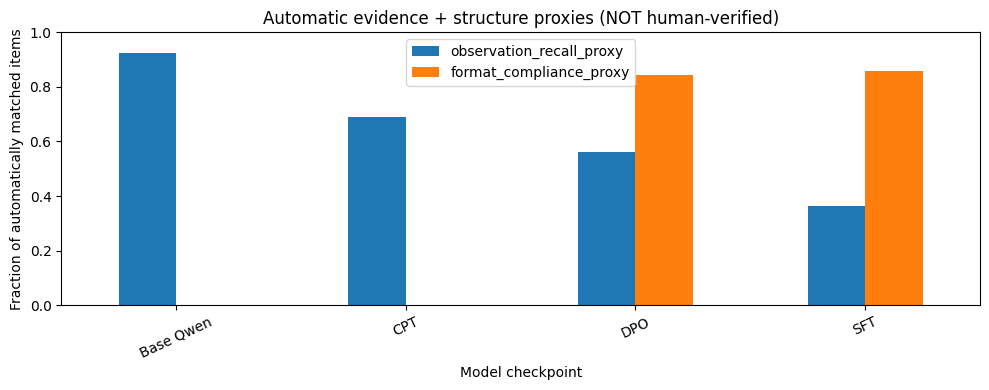

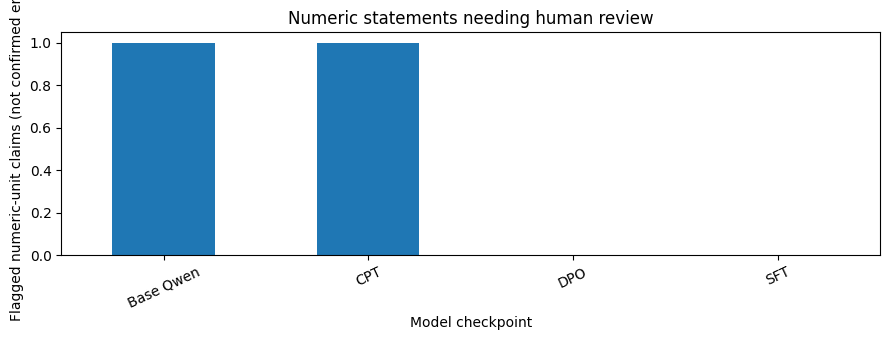

In [14]:
summary=(metrics.groupby('stage',as_index=False)
         .agg(observation_recall_proxy=('observation_recall_proxy','mean'),
              format_compliance_proxy=('format_compliance_proxy','mean'),
              flagged_numeric_claims=('number_claim_flags','sum'),
              mean_latency_s=('latency_s','mean'),
              cases=('id','nunique')))
display(summary.round(3))
ax=summary.plot.bar(x='stage',y=['observation_recall_proxy','format_compliance_proxy'],
                    figsize=(10,4),rot=25,ylim=(0,1),legend=True)
ax.set_ylabel('Fraction of automatically matched items')
ax.set_xlabel('Model checkpoint')
ax.set_title('Automatic evidence + structure proxies (NOT human-verified)')
plt.tight_layout()
plt.savefig(OUT/'proxy_scores_by_stage.png',dpi=170,bbox_inches='tight')
plt.show()

ax2=summary.plot.bar(x='stage',y='flagged_numeric_claims',figsize=(9,3.5),rot=25,legend=False)
ax2.set_ylabel('Flagged numeric-unit claims (not confirmed errors)')
ax2.set_xlabel('Model checkpoint')
ax2.set_title('Numeric statements needing human review')
plt.tight_layout()
plt.savefig(OUT/'numeric_claim_flags.png',dpi=170,bbox_inches='tight')
plt.show()

In [15]:
# Side-by-side evidence audit. Change TARGET_ID to investigate a failure case.
TARGET_ID='P-883'
selected=[r for r in rows if r['id']==TARGET_ID]
for r in selected:
    print('\n'+'='*80+'\n'+r['stage']+'\n'+'='*80)
    print(r['response'][:5000])
print('\nEVIDENCE CHECKLIST (automated proxy):')
pivot=audit[audit['id']==TARGET_ID].pivot(index='evidence',columns='stage',values='proxy_present')
display(pivot)
print('Do not interpret presence as proof of correct fact attribution or negation handling.')


Base Qwen
**Observations:**
- The pump maintained steady discharge flow, indicating that the pump is functioning as expected.
- The casing briefly shuddered twice after a speed change, which could be a sign of a mechanical issue.
- A clicking sound was heard at the discharge pipe support, which could indicate a mechanical issue.
- The pressure display showed 4.1 bar, which is within the normal range for the pump.
- The bearing temperature was not measured, which is a critical piece of information to determine the health of the pump.
- The unit remained online for monitoring, which is a good sign.

**Unverified Causes:**
- The clicking sound at the discharge pipe support could be caused by a loose or damaged support, or a loose or damaged pipe.
- The brief shuddering could be caused by a loose or damaged casing, or a loose or damaged shaft.
- The lack of bearing temperature measurement is a critical piece of information to determine the health of the pump.

**Missing Information:**
- T

stage,Base Qwen,CPT,DPO,SFT
evidence,,,,
4.1 bar,1,1,0,0
clicking,1,1,0,0
monitored,1,1,0,0
steady flow,1,1,0,0
temperature missing,1,1,0,0
two shudders,1,1,0,0


Do not interpret presence as proof of correct fact attribution or negation handling.


In [17]:
summary.to_csv(OUT/'stage_summary_proxy.csv',index=False)
package={
 'title':'Industrial LLM Post-Training Evaluation',
 'evaluation_type':'synthetic_independent_ID_holdout_with_lexical_proxies',
 'limitations':['Synthetic samples','Exact IDs checked, semantic overlap not ruled out',
                'Regex scores are unverified lexical proxies, not factual accuracy',
                'Numeric flags require manual inspection','No statistical superiority claim'],
 'models':list(STAGES), 'test_cases':[{'id':c['id'],'note':c['note'],
                  'evidence_items':[label for label,_ in c['evidence']]} for c in CASES],
 'outputs':rows,'proxy_metrics':report_rows,
 'stage_summary_proxy':summary.to_dict(orient='records'),
}
(OUT/'streamlit_evaluation_export.json').write_text(json.dumps(package,indent=2,ensure_ascii=False),encoding='utf-8')
print('Saved:')
for p in sorted(OUT.iterdir()): print(' -',p.name)
print('Actual completed runs:',len(rows),'out of',len(STAGES)*len(CASES))

Saved:
 - automated_proxy_scores.csv
 - checkpoint_outputs.jsonl
 - evidence_manual_review_template.csv
 - numeric_claim_flags.png
 - proxy_scores_by_stage.png
 - stage_summary_proxy.csv
 - streamlit_evaluation_export.json
Actual completed runs: 40 out of 40


**Part 3: Human Evaluation**

In [18]:

import pandas as pd
from pathlib import Path

rows = read_results()
case_by_id = {c["id"]: c for c in CASES}

responses = {
    (r["id"], r["stage"]): r["response"]
    for r in rows
}

review_file = OUT / "evidence_reviewed.csv"

review = audit[["id", "stage", "evidence", "proxy_present"]].copy()

review["technician_note"] = review["id"].map(
    lambda i: case_by_id[i]["note"]
)

review["model_response"] = [
    responses[(i, s)]
    for i, s in zip(review["id"], review["stage"])
]

review["verified_present"] = pd.NA
review["reviewer_notes"] = ""

if not review_file.exists():
    review.to_csv(review_file, index=False)
    print("Created:", review_file)
else:
    print("Existing review preserved:", review_file)

print("Evidence items:", len(review))
display(review.head())


Created: /content/drive/MyDrive/llm-post-training-experimental-study/results/evaluation_05/evidence_reviewed.csv
Evidence items: 212


,id,stage,evidence,proxy_present,technician_note,model_response,verified_present,reviewer_notes
0,P-883,Base Qwen,steady flow,1,"Pump P-883 maintained steady discharge flow, b...",**Observations:**\n- The pump maintained stead...,<NA>,
1,P-883,Base Qwen,two shudders,1,"Pump P-883 maintained steady discharge flow, b...",**Observations:**\n- The pump maintained stead...,<NA>,
2,P-883,Base Qwen,clicking,1,"Pump P-883 maintained steady discharge flow, b...",**Observations:**\n- The pump maintained stead...,<NA>,
3,P-883,Base Qwen,4.1 bar,1,"Pump P-883 maintained steady discharge flow, b...",**Observations:**\n- The pump maintained stead...,<NA>,
4,P-883,Base Qwen,temperature missing,1,"Pump P-883 maintained steady discharge flow, b...",**Observations:**\n- The pump maintained stead...,<NA>,


**Unsupported claims audit**

In [19]:

error_file = OUT / "error_reviewed.csv"

error_review = pd.DataFrame([
    {
        "id": r["id"],
        "stage": r["stage"],
        "technician_note": r["note"],
        "model_response": r["response"],
        "unsupported_observation": pd.NA,
        "unsupported_interpretation": pd.NA,
        "truncated": pd.NA,
        "reviewer_notes": ""
    }
    for r in rows
])

if not error_file.exists():
    error_review.to_csv(error_file, index=False)
    print("Created:", error_file)
else:
    print("Existing error review preserved:", error_file)

print("Reports to review:", len(error_review))
display(error_review.head(3))


Created: /content/drive/MyDrive/llm-post-training-experimental-study/results/evaluation_05/error_reviewed.csv
Reports to review: 40


,id,stage,technician_note,model_response,unsupported_observation,unsupported_interpretation,truncated,reviewer_notes
0,P-883,Base Qwen,"Pump P-883 maintained steady discharge flow, b...",**Observations:**\n- The pump maintained stead...,<NA>,<NA>,<NA>,
1,HP-951,Base Qwen,Hydraulic press HP-951 briefly jerked while lo...,**Title:** Hydraulic Press HP-951 Maintenance ...,<NA>,<NA>,<NA>,
2,HX-842,Base Qwen,Heat exchanger HX-842 showed a gradual rise in...,**Observations:**\n- Heat exchanger HX-842 sho...,<NA>,<NA>,<NA>,


**Calculate human verified scores**

In [26]:
review_file = OUT / "evidence_reviewed.csv"
error_file = OUT / "error_reviewed csv.csv"
ev = pd.read_csv(review_file)
er = pd.read_csv(error_file)

evidence_keys = ["id", "stage", "evidence"]
report_keys = ["id", "stage"]

# Check identifiers and prevent duplicate records.
assert not ev.duplicated(evidence_keys).any()
assert not er.duplicated(report_keys).any()

expected_evidence = set(
    map(tuple, audit[evidence_keys].itertuples(index=False, name=None))
)
actual_evidence = set(
    map(tuple, ev[evidence_keys].itertuples(index=False, name=None))
)
assert actual_evidence == expected_evidence, "Evidence review rows do not match."

expected_reports = {(r["id"], r["stage"]) for r in rows}
actual_reports = set(
    map(tuple, er[report_keys].itertuples(index=False, name=None))
)
assert actual_reports == expected_reports, "Report review rows do not match."

review_cols = [
    (ev, "verified_present"),
    (er, "unsupported_observation"),
    (er, "unsupported_interpretation"),
    (er, "truncated")
]

for df, col in review_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    assert df[col].notna().all(), f"Complete the {col} column."
    assert df[col].isin([0, 1]).all(), f"{col} must contain 0 or 1."

# Calculate evidence recall per report.
case_recall = (
    ev.groupby(["id", "stage"], as_index=False)["verified_present"]
      .mean()
      .rename(columns={"verified_present": "verified_recall"})
)

case_scores = metrics.merge(
    case_recall, on=["id", "stage"], validate="one_to_one"
)

case_scores = case_scores.merge(
    er[[
        "id", "stage",
        "unsupported_observation",
        "unsupported_interpretation",
        "truncated"
    ]],
    on=["id", "stage"],
    validate="one_to_one"
)

case_scores["any_unsupported_claim"] = (
    (case_scores["unsupported_observation"] == 1) |
    (case_scores["unsupported_interpretation"] == 1)
).astype(int)

# Average each metric across scenarios.
stage_scores = case_scores.groupby(
    "stage", as_index=False
).agg(
    verified_recall=("verified_recall", "mean"),
    schema_compliance=("format_compliance_proxy", "mean"),
    #unsupported_reports=("any_unsupported_claim", "sum"),
    #unsupported_observations=("unsupported_observation", "sum"),
    #unsupported_interpretations=("unsupported_interpretation", "sum"),
    truncated_reports=("truncated", "sum"),
    scenarios=("id", "nunique")
)

display(stage_scores.round(3))


,stage,verified_recall,schema_compliance,truncated_reports,scenarios
0,Base Qwen,0.943,0.000,3,10
1,CPT,0.658,0.000,1,10
2,DPO,0.583,0.843,0,10
3,SFT,0.427,0.857,0,10


# **Final verified graphs**

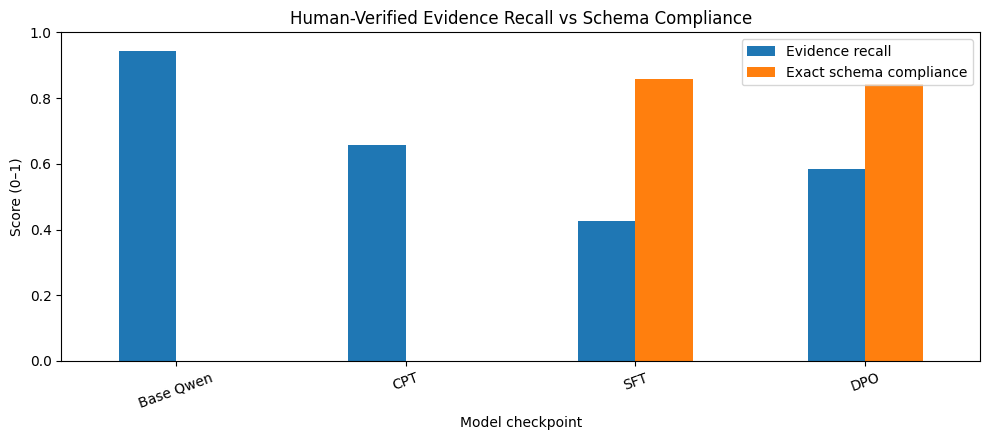

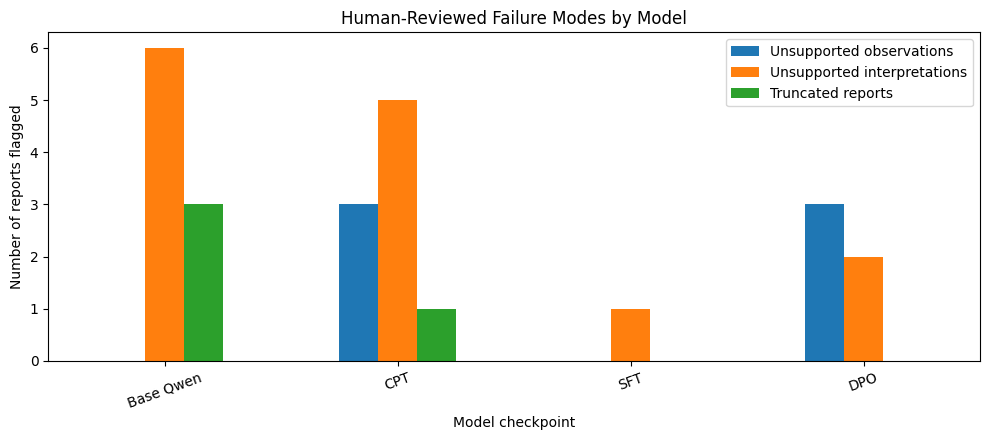

In [30]:

import matplotlib.pyplot as plt

order = [s for s in STAGES if s in set(stage_scores["stage"])]
plot_df = stage_scores.set_index("stage").loc[order]

# Graph 1: Evidence recall vs exact schema compliance
ax = plot_df[
    ["verified_recall", "schema_compliance"]
].plot.bar(
    figsize=(10, 4.5),
    rot=20,
    ylim=(0, 1)
)

ax.set_title("Human-Verified Evidence Recall vs Schema Compliance")
ax.set_ylabel("Score (0–1)")
ax.set_xlabel("Model checkpoint")
ax.legend(["Evidence recall", "Exact schema compliance"])

plt.tight_layout()
plt.savefig(
    OUT / "final_recall_schema.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()


# Graph 2: Human-reviewed failure modes
# Calculate directly from case_scores to avoid column-name mismatches.

failure_cols = [
    "unsupported_observation",
    "unsupported_interpretation",
    "truncated"
]

failure_counts = (
    case_scores
    .groupby("stage")[failure_cols]
    .sum()
    .reindex(order)
    .fillna(0)
)

ax = failure_counts.plot.bar(
    figsize=(10, 4.5),
    rot=20
)

ax.set_title("Human-Reviewed Failure Modes by Model")
ax.set_ylabel("Number of reports flagged")
ax.set_xlabel("Model checkpoint")

ax.legend([
    "Unsupported observations",
    "Unsupported interpretations",
    "Truncated reports"
])

plt.tight_layout()

plt.savefig(
    OUT / "final_failure_modes.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()



In [31]:
print(metrics.columns.tolist())

display(
    metrics.groupby("stage")["format_compliance_proxy"]
    .agg(["count", "min", "max", "mean"])
)

['id', 'stage', 'observation_recall_proxy', 'format_compliance_proxy', 'number_claim_flags', 'flagged_measurements', 'latency_s']


,count,min,max,mean
stage,,,,
Base Qwen,10,0.000000,0.000000,0.000000
CPT,10,0.000000,0.000000,0.000000
DPO,10,0.714286,0.857143,0.842857
SFT,10,0.857143,0.857143,0.857143


Base Qwen retains more source information but can produce long, speculative, incomplete reports.



Continued pretraining does not necessarily improve downstream report quality.



SFT improves structured reporting while sacrificing evidence completeness.



DPO partially recovers evidence but does not consistently eliminate unsupported claims.

In [33]:

import re
import pandas as pd

required_fields = [
    "Equipment",
    "Reported issue",
    "Observed evidence",
    "Possible contributors (not confirmed)",
    "Missing information",
    "Recommended follow-up",
    "Assessment"
]

diagnostics = []

for r in read_results():
    if r["stage"] not in ["SFT", "DPO"]:
        continue

    response = r["response"]

    row = {"stage": r["stage"], "id": r["id"]}

    for field in required_fields:
        row[field] = bool(
            re.search(
                re.escape(field) + r"\s*:",
                response,
                flags=re.IGNORECASE
            )
        )

    diagnostics.append(row)

df_fields = pd.DataFrame(diagnostics)

display(
    df_fields.groupby("stage")[required_fields]
    .sum()
    .T
)

display(
    df_fields.loc[
        ~df_fields[required_fields].all(axis=1),
        ["stage", "id"] + required_fields
    ]
)


stage,DPO,SFT
Equipment,10,10
Reported issue,10,10
Observed evidence,10,10
Possible contributors (not confirmed),10,10
Missing information,10,10
Recommended follow-up,10,10
Assessment,10,10


,stage,id,Equipment,Reported issue,Observed evidence,Possible contributors (not confirmed),Missing information,Recommended follow-up,Assessment


In [34]:

import re
import pandas as pd

required_fields = [
    "Equipment",
    "Reported issue",
    "Observed evidence",
    "Possible contributors (not confirmed)",
    "Missing information",
    "Recommended follow-up",
    "Assessment"
]

schema_rows = []

for r in read_results():
    response = r["response"]

    present = [
        bool(re.search(
            re.escape(field) + r"\s*:",
            response,
            flags=re.IGNORECASE
        ))
        for field in required_fields
    ]

    schema_rows.append({
        "id": r["id"],
        "stage": r["stage"],
        "schema_coverage_corrected": sum(present) / 7,
        "full_schema_present": int(all(present))
    })

schema_df = pd.DataFrame(schema_rows)

# Update the verified case-level table.
case_scores = case_scores.drop(
    columns=[
        "schema_coverage_corrected",
        "full_schema_present"
    ],
    errors="ignore"
)

case_scores = case_scores.merge(
    schema_df,
    on=["id", "stage"],
    validate="one_to_one"
)

# Update the stage-level summary.
corrected_stage = (
    case_scores.groupby("stage", as_index=False)
    .agg(
        schema_coverage_corrected=(
            "schema_coverage_corrected", "mean"
        ),
        full_schema_compliance=(
            "full_schema_present", "mean"
        )
    )
)

stage_scores = stage_scores.drop(
    columns=[
        "schema_coverage_corrected",
        "full_schema_compliance"
    ],
    errors="ignore"
)

stage_scores = stage_scores.merge(
    corrected_stage,
    on="stage",
    validate="one_to_one"
)

display(stage_scores.round(3))

# Save corrected results.
case_scores.to_csv(
    OUT / "final_case_scores.csv",
    index=False
)

stage_scores.to_csv(
    OUT / "final_stage_scores.csv",
    index=False
)


,stage,verified_recall,schema_compliance,truncated_reports,scenarios,schema_coverage_corrected,full_schema_compliance
0,Base Qwen,0.943,0.000,3,10,0.100,0.0
1,CPT,0.658,0.000,1,10,0.129,0.0
2,DPO,0.583,0.843,0,10,1.000,1.0
3,SFT,0.427,0.857,0,10,1.000,1.0


In [35]:

# Replace the old schema metric with corrected field coverage
case_scores["schema_compliance"] = (
    case_scores["schema_coverage_corrected"]
)

stage_scores["schema_compliance"] = (
    stage_scores["schema_coverage_corrected"]
)

# Save corrected tables
case_scores.to_csv(
    OUT / "final_case_scores.csv",
    index=False
)

stage_scores.to_csv(
    OUT / "final_stage_scores.csv",
    index=False
)

print("Schema metrics corrected and saved.")
display(stage_scores.round(3))


Schema metrics corrected and saved.


,stage,verified_recall,schema_compliance,truncated_reports,scenarios,schema_coverage_corrected,full_schema_compliance
0,Base Qwen,0.943,0.100,3,10,0.100,0.0
1,CPT,0.658,0.129,1,10,0.129,0.0
2,DPO,0.583,1.000,0,10,1.000,1.0
3,SFT,0.427,1.000,0,10,1.000,1.0


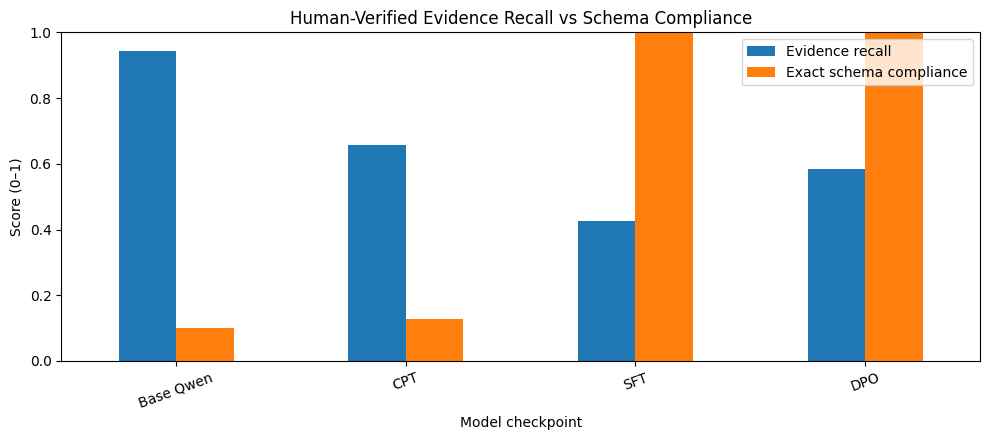

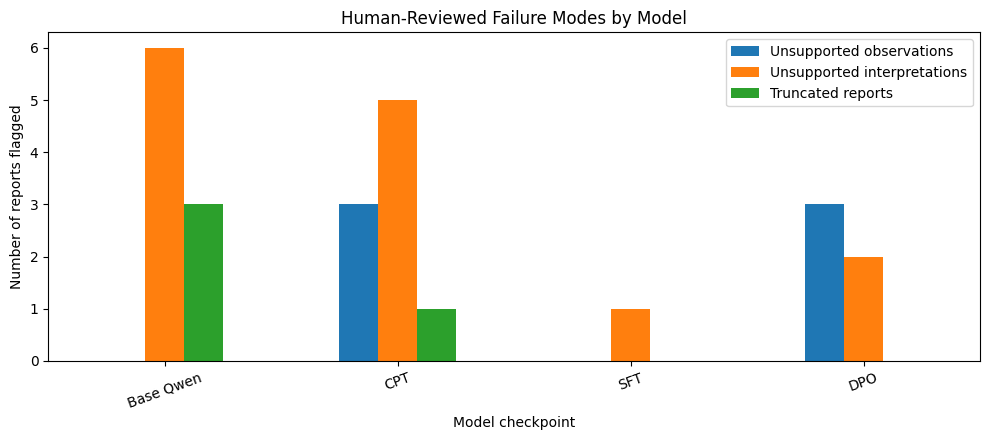

In [36]:

import matplotlib.pyplot as plt

order = [s for s in STAGES if s in set(stage_scores["stage"])]
plot_df = stage_scores.set_index("stage").loc[order]

# Graph 1: Evidence recall vs exact schema compliance
ax = plot_df[
    ["verified_recall", "schema_compliance"]
].plot.bar(
    figsize=(10, 4.5),
    rot=20,
    ylim=(0, 1)
)

ax.set_title("Human-Verified Evidence Recall vs Schema Compliance")
ax.set_ylabel("Score (0–1)")
ax.set_xlabel("Model checkpoint")
ax.legend(["Evidence recall", "Exact schema compliance"])

plt.tight_layout()
plt.savefig(
    OUT / "final_recall_schema.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()


# Graph 2: Human-reviewed failure modes
# Calculate directly from case_scores to avoid column-name mismatches.

failure_cols = [
    "unsupported_observation",
    "unsupported_interpretation",
    "truncated"
]

failure_counts = (
    case_scores
    .groupby("stage")[failure_cols]
    .sum()
    .reindex(order)
    .fillna(0)
)

ax = failure_counts.plot.bar(
    figsize=(10, 4.5),
    rot=20
)

ax.set_title("Human-Reviewed Failure Modes by Model")
ax.set_ylabel("Number of reports flagged")
ax.set_xlabel("Model checkpoint")

ax.legend([
    "Unsupported observations",
    "Unsupported interpretations",
    "Truncated reports"
])

plt.tight_layout()

plt.savefig(
    OUT / "final_failure_modes.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()



1. Base Qwen retains the most evidence. It achieves 94.3% recall but is more verbose, produces unsupported interpretations, and sometimes truncates.

2. SFT produces the cleanest, most standardized outputs. All seven fields appear in every report, and it has the fewest flagged unsupported claims. However, it preserves the least evidence.

3. DPO recovers some evidence. Compared with SFT, it improves recall by 15.6 percentage points, but also introduces additional unsupported observations.

4. CPT exhibits a different failure mode. It retains more information than SFT but produces repetitive or poorly supported technical conclusions.

**Saving metrics and exporting results**

In [37]:

import json

# Save verified scores.
case_scores.to_csv(
    OUT / "final_case_scores.csv", index=False
)

stage_scores.to_csv(
    OUT / "final_stage_scores.csv", index=False
)

# Export results for the Streamlit dashboard.
package = {
    "project": "LLM Post-Training and Alignment",
    "model": "Qwen2.5-1.5B",
    "evaluation": {
        "scenarios": len(CASES),
        "method": "Human-reviewed evidence and failure-mode assessment",
        "dataset": "Synthetic industrial maintenance notes"
    },
    "stage_scores": stage_scores.to_dict(orient="records"),
    "case_scores": case_scores.to_dict(orient="records"),
    "model_outputs": rows
}

with open(
    OUT / "streamlit_evaluation_verified.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(package, f, indent=2, ensure_ascii=False)

# Produce a README-ready Markdown table.
table = stage_scores.round(3).to_markdown(index=False)

summary = f"""# Comparative Evaluation Results

## Experimental Setup

- Base model: Qwen2.5-1.5B
- Checkpoints: Base Qwen, CPT, SFT, DPO
- Evaluation scenarios: {len(CASES)} synthetic technician notes
- Evidence preservation: Human-reviewed
- Schema compliance: Automated exact-field matching
- Unsupported claims: Human-reviewed report-level flags

## Results

{table}

## Interpretation

This evaluation compares evidence preservation, report standardization,
unsupported claims, and truncation across the four model stages.

The results are descriptive and do not establish industrial reliability.
DPO preference accuracy must be interpreted separately from downstream
report quality.

## Limitations

- Small, synthetic test benchmark.
- Potential semantic similarities between training and test scenarios.
- Single-reviewer judgments without independent adjudication.
- Exact schema compliance does not measure overall report readability.
- The contribution of continued pretraining is not isolated without
  a direct-SFT control experiment.
"""

summary_path = OUT / "final_evaluation_summary.md"
summary_path.write_text(summary, encoding="utf-8")

print("Saved final outputs to:", OUT)
print("\nREADME-ready results:\n")
print(table)


Saved final outputs to: /content/drive/MyDrive/llm-post-training-experimental-study/results/evaluation_05

README-ready results:

| stage     |   verified_recall |   schema_compliance |   truncated_reports |   scenarios |   schema_coverage_corrected |   full_schema_compliance |
|:----------|------------------:|--------------------:|--------------------:|------------:|----------------------------:|-------------------------:|
| Base Qwen |             0.943 |               0.1   |                   3 |          10 |                       0.1   |                        0 |
| CPT       |             0.658 |               0.129 |                   1 |          10 |                       0.129 |                        0 |
| DPO       |             0.583 |               1     |                   0 |          10 |                       1     |                        1 |
| SFT       |             0.427 |               1     |                   0 |          10 |                       1     |    